# Notebook 2: from a score to a decision (calibration, the re-run rule, and savings)

**Where we are.** Notebook 1 gave us a model that ranks failed jobs a little better than guessing. Two problems remain:

1. Its probabilities are **not honest** (when it says 20% flaky, the real figure is about 68%).
2. A probability is not a **decision**. A developer needs "re-run it automatically, or send it to a human?"

**What this notebook does**
- Step 1: choose the two models we compare
- Step 2: make the probabilities honest (*calibration*), without peeking at the test data
- Step 3: turn a probability into a re-run decision using costs
- Step 4: count what the rule would have saved on your real data
- Step 5: put error bars on everything (which differences are real?)
- Step 6: stress-test the assumptions

Same rules as before: read the text, guess, run the cell, check your guess. Answer the **Think** boxes in your own words.

## Step 0: Load the data and tools

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold
from baselines import load_main, fit_predict, metrics, GROUPS

os.makedirs("results", exist_ok=True)
pd.set_option("display.width", 140)
data = load_main()
y = data["y"].astype(int).values                       # 1 = flaky, 0 = real
d_min = (data["job_duration_s"].fillna(data["job_duration_s"].median()) / 60).values  # minutes
print(len(data), "jobs,", data["repo"].nunique(), "projects,", f"{y.mean():.0%} flaky")
print(f"median job length: {np.median(d_min):.1f} min,  mean: {d_min.mean():.1f} min")

2370 jobs, 25 projects, 75% flaky
median job length: 7.8 min,  mean: 13.1 min


## Step 1: Two models to compare

- **FULL**: all five feature groups (what Notebook 1 called "all groups")
- **LEAN**: only `history` (the project's recent failure rate) and `run` (how many jobs failed in the same run)

*Why LEAN?* Notebook 1's ablation showed that `history` alone scored best on unseen projects (0.384 against 0.316 for everything), and the other groups looked like noise.

**An honest warning.** We chose LEAN after *looking at the test results*. That makes its score slightly optimistic, because we picked the winner on the same data that we score it on. A reviewer could object. We handle this two ways: we also report FULL, which was chosen in advance, and we put error bars on the comparison in Step 5. Write this down as a limitation in your report.

In [2]:
FULL = list(GROUPS)
LEAN = ["history", "run"]
print("FULL uses:", FULL)
print("LEAN uses:", LEAN)

FULL uses: ['context', 'job', 'history', 'run', 'log']
LEAN uses: ['history', 'run']


## Step 2: Calibration, making the probabilities honest

**The idea.** A model gives a raw score. Calibration learns a small correction: "when the raw score is 0.3, the real flaky rate was 0.68, so report 0.68 instead."

**Two correction methods**
- *Platt scaling:* fits a smooth S-curve. Few moving parts, good for small data.
- *Isotonic:* fits a step-shaped curve that only goes up. More flexible, but with little data it can overfit.

**The trap.** If we fit the correction using the same jobs we then score, we cheat. So we do it in layers (a **nested** split), always by project:

```
outer split: hold out some projects  ->  these are the TEST projects
   inner split inside the other projects:
        the model predicts jobs it did not train on  ->  we learn the correction from these
   train the final model on all the non-test projects
   apply the correction to the test projects' scores
```

No test project ever influences the model or the correction.

In [3]:
def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

class Platt:
    def fit(self, s, yy):
        self.m = LogisticRegression(C=1e6).fit(logit(s).reshape(-1, 1), yy); return self
    def predict(self, s):
        return self.m.predict_proba(logit(s).reshape(-1, 1))[:, 1]

class Isotonic:
    def fit(self, s, yy):
        self.m = IsotonicRegression(out_of_bounds="clip", y_min=0.001, y_max=0.999).fit(s, yy); return self
    def predict(self, s):
        return self.m.predict(s)

def nested_predictions(groups, outer=5, inner=4):
    """Returns raw, platt, isotonic and dummy predictions for every job.
    Each job is predicted by models that never saw its project."""
    n = len(data)
    out = {k: np.full(n, np.nan) for k in ("raw", "platt", "isotonic", "dummy")}
    for tr, te in GroupKFold(outer).split(data, groups=data["repo"]):
        train, test = data.iloc[tr], data.iloc[te]
        # inner loop: scores for training jobs, each from a model that did not see that job's project
        s_in = np.full(len(train), np.nan)
        for a, b in GroupKFold(inner).split(train, groups=train["repo"]):
            s_in[b] = fit_predict("logreg", groups, train.iloc[a], train.iloc[b])
        s_te = fit_predict("logreg", groups, train, test)
        y_tr = train["y"].astype(int).values
        out["raw"][te] = s_te
        out["platt"][te] = Platt().fit(s_in, y_tr).predict(s_te)
        out["isotonic"][te] = Isotonic().fit(s_in, y_tr).predict(s_te)
        out["dummy"][te] = y_tr.mean()
    return out

preds = {"FULL": nested_predictions(FULL), "LEAN": nested_predictions(LEAN)}
print("done")

done


**Reading the Brier score.** Brier measures how far the probabilities are from what happened. **Lower is better.** The `dummy` row is a model that always says "the usual flaky rate". Any serious model must beat it, or its probabilities are worse than useless.

In [4]:
rows = []
for mname in ("FULL", "LEAN"):
    for kind in ("raw", "platt", "isotonic"):
        m = metrics(y, preds[mname][kind])
        rows.append({"model": mname, "version": kind, "brier": m["brier"], "ece": m["ece"],
                     "pr_auc_real": m["pr_auc_real"], "roc_auc": m["roc_auc"]})
m = metrics(y, preds["LEAN"]["dummy"])
rows.append({"model": "dummy", "version": "-", "brier": m["brier"], "ece": m["ece"],
             "pr_auc_real": m["pr_auc_real"], "roc_auc": m["roc_auc"]})
cal_table = pd.DataFrame(rows).round(3)
cal_table

,model,version,brier,ece,pr_auc_real,roc_auc
0,FULL,raw,0.220,0.120,0.316,0.605
1,FULL,platt,0.185,0.013,0.297,0.571
2,FULL,isotonic,0.187,0.044,0.276,0.569
3,LEAN,raw,0.178,0.038,0.379,0.652
4,LEAN,platt,0.179,0.027,0.365,0.639
5,LEAN,isotonic,0.180,0.045,0.355,0.637
6,dummy,-,0.188,0.000,0.226,0.438


**What to look for**
- Does `platt` or `isotonic` lower the Brier score compared with `raw`?
- Is any version better than `dummy`? If not, the probabilities don't help yet.
- Calibration changes *how confident* the model sounds. It should change `pr_auc_real` and `roc_auc` (which measure the *ranking*) only a little. Small shifts are normal: each test fold learns its own correction and we then pool the folds.

**Think 1.** Compare the Brier scores. Which model and version would you use? Is it clearly better than `dummy`? Write it down.

*My answer:*

### The reliability curve before and after

Same picture as Notebook 1. Each dot is a group of jobs with similar predictions: left/bottom is what the model said, side is what really happened. On the diagonal means honest.

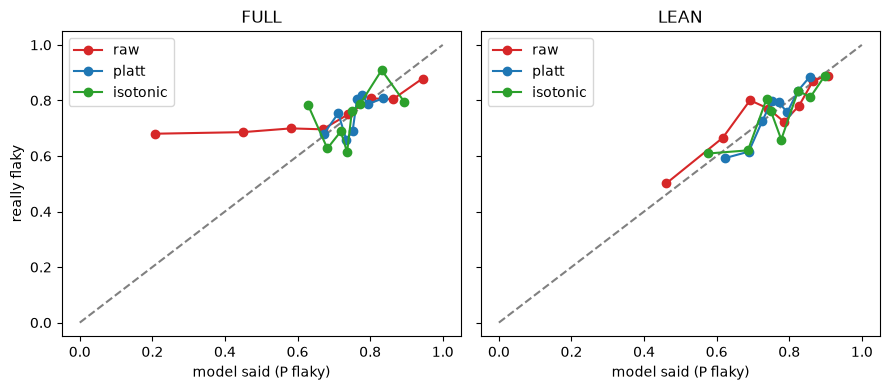

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, mname in zip(axes, ("FULL", "LEAN")):
    ax.plot([0, 1], [0, 1], "--", c="gray")
    for kind, col in (("raw", "tab:red"), ("platt", "tab:blue"), ("isotonic", "tab:green")):
        frac, mean_p = calibration_curve(y, preds[mname][kind], n_bins=8, strategy="quantile")
        ax.plot(mean_p, frac, "o-", c=col, label=kind)
    ax.set_title(mname); ax.set_xlabel("model said (P flaky)"); ax.legend()
axes[0].set_ylabel("really flaky")
plt.tight_layout(); plt.savefig("results/calibration_before_after.png", dpi=150)

**Think 2.** Is the blue/green line closer to the diagonal than the red one? Is there a part of the curve (low or high predictions) that stays off the diagonal even after the correction? What does that tell you about whether the model can *recognise* real failures?

*My answer:*

## Step 3: From a probability to a decision

For each failed job the model gives **p = probability it is flaky**. The options:
- **Re-run it automatically.** If it was flaky, great: no human had to notice and click. If it was really broken, we wasted machine time, and the developer waited for a pointless re-run.
- **Leave it for a human.**

**Costs, in "machine-minutes".** We need to put both mistakes on one scale.

| Situation | Cost |
|---|---|
| Flaky job, **not** re-run | a human has to step in: **X** machine-minutes |
| Real job, re-run | wasted compute + the developer waits: **(1 + W) × job length** |
| Flaky job re-run, real job left alone | 0 (the right call) |

- **job length** comes from your data (`job_duration_s`), and it is known the moment the job fails.
- **X** is how many machine-minutes a human intervention is worth. **You said you aren't sure, so we test X = 2, 5, 15, 45 and 135** instead of choosing one.
- **W** says how much the developer's waiting counts. W = 1 means waiting counts as much as the wasted compute; W = 0 ignores waiting.

**The rule.** Re-run when the expected saving is bigger than the expected waste:

> re-run if **p × X > (1 − p) × (1 + W) × job length**

We don't tune a threshold on the test data. The costs set it. If the probabilities are honest (Step 2), this is the best you can do. That is why calibration came first.

In [6]:
W = 1.0
X_VALUES = [2, 5, 15, 45, 135]

def cost_rule(p, X, W=W):
    return p * X > (1 - p) * (1 + W) * d_min

def evaluate(rerun, X, W=W, real_weight=1.0):
    flaky = y == 1
    human = int((flaky & ~rerun).sum())
    real_rerun = (~flaky) & rerun
    wasted = float(d_min[real_rerun].sum())
    cost = X * human + real_weight * (1 + W) * wasted
    return {"cost": cost, "human_interventions": human,
            "flaky_rerun": int((flaky & rerun).sum()),
            "real_rerun": int(real_rerun.sum()), "wasted_machine_min": wasted}
print("example: a 10-minute job, X=15, W=1 -> re-run if p > ", round(2*10/(15+2*10), 2))

example: a 10-minute job, X=15, W=1 -> re-run if p >  0.57


**Read the example line.** For a 10-minute job and X = 15, the rule says "re-run only if you are more than 57% sure it is flaky". For a 2-minute job the bar is much lower, because a wrong re-run is cheap. For a 100-minute job the bar is very high. The rule adapts to the job. This is what "cost-aware" means.

## Step 4: What would the rule have saved?

We compare four policies on all your jobs:
- **never**: a human handles every failure (no automation)
- **always**: re-run every failure automatically (what many teams already do)
- **model**: our cost rule, using the calibrated probabilities
- **oracle**: re-run exactly the flaky ones (a perfect model, the ceiling)

**The key comparison is `model` against `always`.** "Always re-run" is a strong, cheap baseline when most failures are flaky (about 75% here). The model only earns its place if it beats that.

In [7]:
BEST = "platt"      # change to "isotonic" or "raw" to compare
rows = []
for mname in ("FULL", "LEAN"):
    p = preds[mname][BEST]
    for X in X_VALUES:
        pol = {"never": np.zeros(len(y), bool), "always": np.ones(len(y), bool),
               "model": cost_rule(p, X), "oracle": (y == 1)}
        res = {k: evaluate(v, X) for k, v in pol.items()}
        rows.append({"model": mname, "X": X,
                     "cost_never": res["never"]["cost"], "cost_always": res["always"]["cost"],
                     "cost_model": res["model"]["cost"], "cost_oracle": res["oracle"]["cost"],
                     "saving_vs_never_%": 100 * (1 - res["model"]["cost"] / res["never"]["cost"]),
                     "saving_vs_always_%": 100 * (1 - res["model"]["cost"] / res["always"]["cost"]),
                     "real_rerun_model": res["model"]["real_rerun"],
                     "real_rerun_always": res["always"]["real_rerun"],
                     "human_interv_model": res["model"]["human_interventions"]})
sav = pd.DataFrame(rows).round(1)
sav

,model,X,cost_never,cost_always,cost_model,cost_oracle,saving_vs_never_%,saving_vs_always_%,real_rerun_model,real_rerun_always,human_interv_model
0,FULL,2,3556.0,16873.9,2518.2,0.0,29.2,85.1,204,592,1112
1,FULL,5,8890.0,16873.9,5495.6,0.0,38.2,67.4,289,592,832
2,FULL,15,26670.0,16873.9,10776.9,0.0,59.6,36.1,469,592,279
3,FULL,45,80010.0,16873.9,15712.2,0.0,80.4,6.9,584,592,30
4,FULL,135,240030.0,16873.9,16863.6,0.0,93.0,0.1,590,592,8
5,LEAN,2,3556.0,16873.9,2392.8,0.0,32.7,85.8,193,592,1070
6,LEAN,5,8890.0,16873.9,5357.2,0.0,39.7,68.3,285,592,823
7,LEAN,15,26670.0,16873.9,9796.6,0.0,63.3,41.9,435,592,280
8,LEAN,45,80010.0,16873.9,13177.9,0.0,83.5,21.9,561,592,28
9,LEAN,135,240030.0,16873.9,16863.6,0.0,93.0,0.1,590,592,8


**How to read each column**
- `cost_*` is the total cost under each policy (smaller is better).
- `saving_vs_never_%` is how much better the model is than doing nothing. `saving_vs_always_%` is how much better it is than re-running everything. **Negative means the model is worse.**
- `real_rerun_model` / `real_rerun_always` is the number of **real failures that got re-run** (the mentor's "genuine failures misclassified as transient"). Fewer is better.
- `human_interv_model` is how many flaky jobs still needed a person.

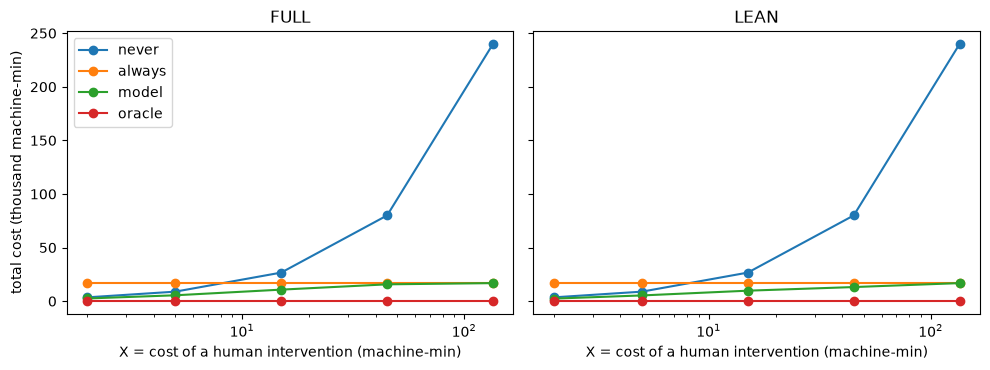

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, mname in zip(axes, ("FULL", "LEAN")):
    s = sav[sav.model == mname].set_index("X")
    for col, lab in (("cost_never", "never"), ("cost_always", "always"),
                     ("cost_model", "model"), ("cost_oracle", "oracle")):
        ax.plot(s.index, s[col] / 1000, "o-", label=lab)
    ax.set_xscale("log"); ax.set_title(mname); ax.set_xlabel("X = cost of a human intervention (machine-min)")
axes[0].set_ylabel("total cost (thousand machine-min)"); axes[0].legend()
plt.tight_layout(); plt.savefig("results/policy_costs.png", dpi=150)

**Think 3.** (a) For small X (a human intervention is cheap), which policy wins? For large X? Why? (b) At which X does the `model` policy start to beat `always`, if ever? (c) How far is `model` from `oracle`? That gap is the most the model could still improve.

*My answer:*

## Step 4b: How much of the saving is just job length?

In Step 4 the rule skipped long jobs, because a wasted re-run of a long job is expensive. **Job length is known without any model.** So part of the saving may come from the job length alone, not from the model's prediction.

To test that, we build a **duration-only** rule: the same cost rule, but every job gets the *same* probability (the overall flaky rate of the training projects). Nothing about the failure itself is used, only how long the job is.

The number that matters is the last column: **how much does the model save compared with the duration-only rule?** If it is close to 0%, the model adds little beyond job length.

In [9]:
p_dur = preds["LEAN"]["dummy"]          # same probability for every job = the usual flaky rate
rows = []
for X in X_VALUES:
    c_nev = evaluate(np.zeros(len(y), bool), X)["cost"]
    c_alw = evaluate(np.ones(len(y), bool), X)["cost"]
    c_dur = evaluate(cost_rule(p_dur, X), X)["cost"]
    c_mod = evaluate(cost_rule(preds["LEAN"][BEST], X), X)["cost"]
    rows.append({"X": X, "cost_never": c_nev, "cost_always": c_alw,
                 "cost_duration_only": c_dur, "cost_model": c_mod,
                 "duration_only_vs_always_%": 100 * (1 - c_dur / c_alw),
                 "model_vs_always_%": 100 * (1 - c_mod / c_alw),
                 "model_vs_duration_only_%": 100 * (1 - c_mod / c_dur)})
dur_table = pd.DataFrame(rows).round(1)
dur_table

,X,cost_never,cost_always,cost_duration_only,cost_model,duration_only_vs_always_%,model_vs_always_%,model_vs_duration_only_%
0,2,3556.0,16873.9,2583.0,2392.8,84.7,85.8,7.4
1,5,8890.0,16873.9,5436.8,5357.2,67.8,68.3,1.5
2,15,26670.0,16873.9,11011.3,9796.6,34.7,41.9,11.0
3,45,80010.0,16873.9,15522.7,13177.9,8.0,21.9,15.1
4,135,240030.0,16873.9,17055.0,16863.6,-1.1,0.1,1.1


**Think 3b.** Compare `duration_only_vs_always_%` with `model_vs_always_%`. How much of the model's saving does the simple duration rule already achieve? What is the extra saving of the model on top (last column)? Is that extra worth building and running a model for?

*My answer:*

## Step 5: Error bars, which differences are real?

We have 25 projects. If we had picked a different 25, the numbers would be a bit different. A **bootstrap by project** simulates that: draw 25 projects *with replacement* from our 25, recompute the numbers, and repeat 500 times. The spread of the results shows how much to trust each number.

We compare FULL and LEAN on the *same* resamples, so we can ask directly: **is LEAN better than FULL, or could that be luck?** If the 95% interval for the difference includes 0, we can't claim a difference.

In [10]:
rng = np.random.default_rng(0)
repos = data["repo"].values
by_repo = {r: np.where(repos == r)[0] for r in np.unique(repos)}
names = list(by_repo)
B = 500
X_FOCUS = 15

def policy_cost(idx, rerun, X=X_FOCUS):
    f = (y == 1)[idx]; r = rerun[idx]
    return X * (f & ~r).sum() + (1 + W) * d_min[idx][(~f) & r].sum()

def saving_vs_always(idx, p, X=X_FOCUS):
    return 100 * (1 - policy_cost(idx, cost_rule(p, X), X) / policy_cost(idx, np.ones(len(y), bool), X))

p_dur_all = preds["LEAN"]["dummy"]
def saving_vs_duration(idx, p, X=X_FOCUS):
    return 100 * (1 - policy_cost(idx, cost_rule(p, X), X) / policy_cost(idx, cost_rule(p_dur_all, X), X))

pF, pL = preds["FULL"][BEST], preds["LEAN"][BEST]
res = {k: [] for k in ("pr_full", "pr_lean", "pr_dummy", "sav_full", "sav_lean", "sav_lean_vs_dur")}
for _ in range(B):
    idx = np.concatenate([by_repo[r] for r in rng.choice(names, len(names), replace=True)])
    res["pr_full"].append(average_precision_score(1 - y[idx], 1 - pF[idx]))
    res["pr_lean"].append(average_precision_score(1 - y[idx], 1 - pL[idx]))
    res["pr_dummy"].append(1 - y[idx].mean())            # random guessing = share of real failures
    res["sav_full"].append(saving_vs_always(idx, pF))
    res["sav_lean"].append(saving_vs_always(idx, pL))
    res["sav_lean_vs_dur"].append(saving_vs_duration(idx, pL))
res = {k: np.array(v) for k, v in res.items()}

def ci(a): return f"{np.mean(a):.3f}  [{np.percentile(a, 2.5):.3f}, {np.percentile(a, 97.5):.3f}]"
print("PR-AUC for finding real failures (mean [95% interval])")
print("  random guessing :", ci(res["pr_dummy"]))
print("  FULL            :", ci(res["pr_full"]))
print("  LEAN            :", ci(res["pr_lean"]))
d = res["pr_lean"] - res["pr_full"]
print("  LEAN minus FULL :", ci(d), "  <- if this interval contains 0, no proven difference")
d2 = res["pr_lean"] - res["pr_dummy"]
print("  LEAN minus guessing:", ci(d2))
print(f"\nSaving of the model rule vs 'always re-run' at X={X_FOCUS} (% of cost)")
print("  FULL:", ci(res["sav_full"]))
print("  LEAN:", ci(res["sav_lean"]))
print(f"\nSaving of LEAN vs the DURATION-ONLY rule at X={X_FOCUS} (the model's extra value)")
print("  LEAN:", ci(res["sav_lean_vs_dur"]), "  <- if this contains 0, the model adds nothing beyond job length")

PR-AUC for finding real failures (mean [95% interval])
  random guessing : 0.249  [0.195, 0.304]
  FULL            : 0.301  [0.226, 0.380]
  LEAN            : 0.366  [0.269, 0.491]
  LEAN minus FULL : 0.065  [0.007, 0.154]   <- if this interval contains 0, no proven difference
  LEAN minus guessing: 0.118  [0.059, 0.206]

Saving of the model rule vs 'always re-run' at X=15 (% of cost)
  FULL: 32.445  [-0.698, 62.235]
  LEAN: 38.209  [8.675, 64.525]

Saving of LEAN vs the DURATION-ONLY rule at X=15 (the model's extra value)
  LEAN: 9.236  [-3.610, 21.584]   <- if this contains 0, the model adds nothing beyond job length


**How to read it.** `[a, b]` is a 95% range: if we repeated the study on other projects, we'd expect the result to land in that range 95 times out of 100.

**Think 4.** (a) Does the range for LEAN-minus-guessing contain 0? If it doesn't, the model beats random on new projects. If it does, we can't claim that. (b) Is LEAN really better than FULL, or are they statistically the same? (c) Is the saving versus `always` clearly above 0%? (d) Is the saving versus the duration-only rule above 0%? State your conclusion with the numbers.

*My answer:*

## Step 6: Stress test, what if our assumptions are wrong?

Our data has a **selection bias**. We only know the label of jobs someone chose to re-run. Many *real* failures are never re-run, because developers fix the code instead. So in real life, real failures are probably **more common** than in our data (25%).

We can test that. In the table below, `real_weight` counts every real failure as if there were that many of them. A weight of 3 simulates a world where real failures are three times as common relative to flaky ones. We look at the model's saving versus `always`.

In [11]:
rows = []
p = preds["LEAN"][BEST]
for rw in (1, 2, 4, 8):
    for X in X_VALUES:
        c_m = evaluate(cost_rule(p, X), X, real_weight=rw)["cost"]
        c_a = evaluate(np.ones(len(y), bool), X, real_weight=rw)["cost"]
        c_n = evaluate(np.zeros(len(y), bool), X, real_weight=rw)["cost"]
        rows.append({"real_weight": rw, "X": X,
                     "saving_vs_always_%": 100 * (1 - c_m / c_a),
                     "saving_vs_never_%": 100 * (1 - c_m / c_n)})
stress = pd.DataFrame(rows)
print("saving of the model vs ALWAYS re-run (%)")
print(stress.pivot(index="real_weight", columns="X", values="saving_vs_always_%").round(1))
print("\nsaving of the model vs NEVER re-run (%)")
print(stress.pivot(index="real_weight", columns="X", values="saving_vs_never_%").round(1))

saving of the model vs ALWAYS re-run (%)
X             2     5     15    45   135
real_weight                             
1            85.8  68.3  41.9  21.9  0.1
2            92.2  80.4  54.4  25.6  3.3
4            95.3  86.5  60.6  27.5  4.9
8            96.9  89.6  63.7  28.4  5.7

saving of the model vs NEVER re-run (%)
X             2     5     15    45    135
real_weight                              
1            32.7  39.7  63.3  83.5  93.0
2            25.6  25.8  42.3  68.6  86.4
4            11.4  -2.2   0.3  38.8  73.2
8           -17.1 -58.1 -83.6 -20.7  46.9


**Think 5.** As real failures get more common, what happens to the saving versus `always`? Why does it move that way? What does this tell you about *when* a triage model is worth deploying?

*My answer:*

## Step 7: Save what you need for the next notebook, and write your conclusions

In [12]:
out = data[["repo", "job_id", "run_created_at", "job_duration_s"]].copy()
out["y"] = y
for mname in ("FULL", "LEAN"):
    for kind in ("raw", "platt", "isotonic"):
        out[f"p_{mname}_{kind}"] = preds[mname][kind]
out.to_csv("results/nested_predictions.csv", index=False)
cal_table.to_csv("results/calibration_table.csv", index=False)
sav.to_csv("results/policy_savings.csv", index=False)
print("saved to results/")

saved to results/


**My conclusions (5 to 8 sentences, your own words).** What did calibration fix? Did the model beat `always re-run`, and for which values of X? Which results can you trust and which can't you? What is the biggest limitation? An examiner will ask about exactly these points.

*My conclusions:*